# Test des modules serial et pyserial

Elaboration d'un algorythme de lecture série des données de la carte

In [4]:
import serial
import serial.tools.list_ports
import matplotlib.pyplot as plt
import numpy

In [5]:
#Global variables

measured_tests = []

In [12]:
#Lists all ports
ports = serial.tools.list_ports.comports()

open_ports = ""
descr = ""

for port, desc, hwid in sorted(ports):
        ##print("{}: {} [{}]".format(port, desc, hwid))
        ##print("{}".format(port))
        descr = "{}".format(desc)
        if (descr == "STM32 STLink - ST-Link VCP Ctrl"):
            open_ports = "{}".format(port)

print("Open ports : ", open_ports)

data_serial = serial.Serial(
    port=open_ports,
    baudrate=115200,#576000,#115200,
    parity=serial.PARITY_NONE,
    stopbits=serial.STOPBITS_ONE,
    bytesize=serial.EIGHTBITS

)
data_serial.writeTimeout = 0 
data_serial.isOpen()
print(data_serial)

Open ports :  /dev/ttyACM0
Serial<id=0x7f6958713e50, open=True>(port='/dev/ttyACM0', baudrate=115200, bytesize=8, parity='N', stopbits=1, timeout=None, xonxoff=False, rtscts=False, dsrdtr=False)


In [11]:
data_serial.close()
data_serial.isOpen()

False

In [7]:
data_serial.isOpen()

True

### RX

In [8]:
# =================================
# IDs TX/RX
# =================================

ID_RX_START = b'0x01'
ID_RX_STOP = b'0x02'
ID_RX_PWM_START = b'0x03'
ID_RX_PWM_STOP = b'0x04'
ID_RX_DUTY_SET = b'0x05'
ID_RX_DIR = b'0x06'
ID_RX_VOLTAGE_SET = b'0x07'
ID_RX_SET_MAG = b'0x08'
ID_RX_SET_COMMAND = b'0x09'

ID_RX_ACK = b'0xFF'
ID_RX_CALIBRATE = b'0xFE'
ID_RX_CALIB_ZEROG = b'0xFA'
ID_RX_CALIB_MINUSG = b'0xFB'
ID_RX_CALIB_PLUSG = b'0xFC'

ID_RX_SEND_KP = b'0x0A'
ID_RX_SET_KP = b'0x0B'
ID_RX_SEND_KI = b'0x0C'
ID_RX_SET_KI = b'0x0D'
ID_RX_SEND_KD = b'0x0E'
ID_RX_SET_KD = b'0x0F'

# =================================
# trames
# =================================

def define_trame(msg_id, value, max_size):
    #init
    trame = b''
    byte_length = b''
    
    byte_length = bytes(str(value),'utf-8')
    float_byte_size = len(byte_length)
    index_max_byte = max_size-len(msg_id)-2
    print("index_max_byte :",index_max_byte, " max_size :", max_size)
    trame = msg_id+byte_length[0:index_max_byte]+b';'
    
    #zero filler
    zero_filler = b'0'*(max_size - len(trame)-1)
    trame+= zero_filler
    #EOF Character to end the line, counts as 1 bytes
    trame += bytes('\n', 'utf-8')
    return trame

# =================================
# fonctions d'envoi
# =================================

MSG_MAX_SIZE = 16

def uart_send_start():
    data_serial.write(define_trame(ID_RX_START, 1, MSG_MAX_SIZE))
    
def uart_send_stop():
    data_serial.write(define_trame(ID_RX_STOP, 1, MSG_MAX_SIZE))
    
def uart_send_pwmStart():
    data_serial.write(define_trame(ID_RX_PWM_START, 1, MSG_MAX_SIZE))
    
def uart_send_pwmStop():
    data_serial.write(define_trame(ID_RX_PWM_STOP, 1, MSG_MAX_SIZE))
    
def uart_send_dutyValue(duty_value):
    data_serial.write(define_trame(ID_RX_DUTY_SET, duty_value, MSG_MAX_SIZE))
    
def uart_send_command(command):
    data_serial.write(define_trame(ID_RX_SET_COMMAND, command, MSG_MAX_SIZE))
    
def uart_send_direction(dir_value):
    data_serial.write(define_trame(ID_RX_DIR, dir_value, MSG_MAX_SIZE))
    
def uart_send_voltageValue(voltage_value):
    print("b'' sent : ",data_serial.write(define_trame(ID_RX_VOLTAGE_SET, voltage_value, MSG_MAX_SIZE)))
    
def uart_send_kpAsk(kp_value):
    data_serial.write(define_trame(ID_RX_SET_KP, kp_value, MSG_MAX_SIZE))
    
def uart_send_kpValue():
    data_serial.write(define_trame(ID_RX_SEND_KP, 1, MSG_MAX_SIZE))
    
def uart_send_kiAsk(ki_value):
    data_serial.write(define_trame(ID_RX_SET_KI, ki_value, MSG_MAX_SIZE))
    
def uart_send_kiValue():
    data_serial.write(define_trame(ID_RX_SEND_KI, 1, MSG_MAX_SIZE))
    
def uart_send_kdAsk(kd_value):
    data_serial.write(define_trame(ID_RX_SET_KD, kd_value, MSG_MAX_SIZE))
    
def uart_send_kdValue():
    data_serial.write(define_trame(ID_RX_SEND_KD, 1, MSG_MAX_SIZE))
    
def uart_send_acknowledge():
    data_serial.write(define_trame(ID_RX_ACK, 1, MSG_MAX_SIZE))
    
def uart_send_calibrate():
    data_serial.write(define_trame(ID_RX_CALIBRATE, 1, MSG_MAX_SIZE))
    
def uart_send_calibzeroG():
    data_serial.write(define_trame(ID_RX_CALIB_ZEROG, 1, MSG_MAX_SIZE))
    
def uart_send_calibminusG():
    data_serial.write(define_trame(ID_RX_CALIB_MINUSG, 1, MSG_MAX_SIZE))
    
def uart_send_calibplusG():
    data_serial.write(define_trame(ID_RX_CALIB_PLUSG, 1, MSG_MAX_SIZE))
    
def uart_send_mag(state_int):
    data_serial.write(define_trame(ID_RX_SET_MAG, state_int, MSG_MAX_SIZE))

In [10]:
uart_send_mag(1)

index_max_byte : 10  max_size : 16


In [8]:
uart_send_mag(0)

index_max_byte : 10  max_size : 16


In [9]:
uart_send_start()

index_max_byte : 10  max_size : 16


In [10]:
uart_send_stop()

index_max_byte : 10  max_size : 16


In [61]:
uart_send_dutyValue(100.0)

index_max_byte : 10  max_size : 16


In [62]:
uart_send_dutyValue(0.0)

index_max_byte : 10  max_size : 16


## Calibration accelero

In [12]:
uart_send_calibzeroG()

index_max_byte : 10  max_size : 16


In [13]:
uart_send_calibminusG()

index_max_byte : 10  max_size : 16


In [14]:
uart_send_calibplusG()

index_max_byte : 10  max_size : 16


In [15]:
uart_send_calibrate()

index_max_byte : 10  max_size : 16


## Lecture & Traitement des données

In [20]:
# =================================
# Read
# =================================
def read_data(nline):
    data_serial.reset_input_buffer()
    data_serial.reset_output_buffer()
    
    it = 0
    print("start reading")
    ##error while reading previous values
    ##kinda flush
    data_table = []
    while (it != (nline+50)):
        # Read data out of the buffer until a carraige return / new line is found
        data = (data_serial.readline()).decode()
        data = data.split(";")
        #print(data)
        
        data_table.append(data)
        it += 1;
        #print(it)
    print("out")
    data_table = data_table[50:nline+1]
    return data_table

# =================================
# Processing
# =================================
def compute_data_table(dt):
    ndt = []
    tables = []
    
    for data_line in dt:
        if (((len(data_line)-1) % 2 == 0) and (len(data_line) > 1)):
            data_line[0] = data_line[0].lstrip('\r') #supprime le \r caractere
            
            for i in range(0, len(data_line)):
                if ((i%2) == 1):
                    data_line[i] = float(data_line[i])
        ndt.append(data_line)
    return ndt

# =================================
# Slicing
# =================================
def time_getTable(dt):
    ndt = []
    for data_line in dt:
        if (((len(data_line)-1) % 2 == 0) and (len(data_line) > 1)):
            for k in range(len(data_line)):
                if (type(data_line[k]) == type("0x0")): # "0x01" in data_line[k] only for string
                    if ("0x01" in data_line[k]):
                        ndt.append((data_line[k+1])/1000)
    
    init_time = ndt[0]
    for j in range(len(ndt)):
        ndt[j] = round(ndt[j] - init_time, 3) #3 digit after . as it is divised by 10e3
    
    return ndt

def pwm_getTable(dt):
    ndt = []
    for data_line in dt:
        if (((len(data_line)-1) % 2 == 0) and (len(data_line) > 1)):
            ##print(data_line)
            for k in range(len(data_line)):
                if (type(data_line[k]) == type("0x0")):
                    if ("0x11" in data_line[k]):
                        ndt.append(data_line[k+1])
                    
    return ndt

def adc_getTable(dt):
    ndt = []
    for data_line in dt:
        if (((len(data_line)-1) % 2 == 0) and (len(data_line) > 1)):
            for k in range(len(data_line)):
                if (type(data_line[k]) == type("0x0")):
                    if ("0x09" in data_line[k]):
                        ndt.append(data_line[k+1])
                    
    return ndt

def accel_getTable(dt):
    ndt = []
    for data_line in dt:
        if (((len(data_line)-1) % 2 == 0) and (len(data_line) > 1)):
            for k in range(len(data_line)):
                if (type(data_line[k]) == type("0x0")):
                    if ("0x10" in data_line[k]):
                        ndt.append(data_line[k+1])
                    
    return ndt

def speed_getTable(dt):
    ndt = []
    for data_line in dt:
        #print("DATA LINE :", data_line, len(data_line))
        if (((len(data_line)-1) % 2 == 0) and (len(data_line) > 1)):
            for k in range(len(data_line)):
                if (type(data_line[k]) == type("0x0")):
                    if ("0x12" in data_line[k]):
                        ndt.append(data_line[k+1])
                    
    return ndt

def all_getTable(dt):
    ndt = []
    
    for data_line in dt:
        ndtline = [0]*5
        if (((len(data_line)-1) % 2 == 0) and (len(data_line) > 1)):
            for k in range(len(data_line)):
                if (type(data_line[k]) == type("0x0")):
                    if ("0x01" in data_line[k]):
                        ndtline[0] = ((data_line[k+1])/1000)
                    if ("0x09" in data_line[k]):
                        ndtline[1] = (data_line[k+1])
                    if ("0x10" in data_line[k]):
                        ndtline[2] = (data_line[k+1])
                    if ("0x11" in data_line[k]):
                        ndtline[3] = (data_line[k+1])
                    if ("0x12" in data_line[k]):
                        ndtline[4] = (data_line[k+1])
                        
        ndt.append(ndtline)
        
    init_time = ndt[0][0]
    for j in range(len(ndt)):
        ndt[j][0] = round(ndt[j][0] - init_time, 3) #3 digit after . as it is divised by 10e3
    
    return ndt

### Tests

In [21]:
import time
t0 = time.time()
#data_serial.reset_input_buffer()

data_test = read_data(1000)
t1 = time.time()
print(t1-t0)

start reading
out
10.013788938522339


In [22]:
print(data_test)

[['\r\x000x01', '219711', '0x09', '1.108692', '0x11', '0', '0x12', '0.000000', '\n'], ['\r\x000x01', '219721', '0x09', '1.121036', '0x11', '0', '0x12', '0.000000', '\n'], ['\r\x000x01', '219731', '0x09', '1.108479', '0x11', '0', '0x12', '0.000000', '\n'], ['\r\x000x01', '219741', '0x09', '1.089111', '0x11', '0', '0x12', '0.000000', '\n'], ['\r\x000x01', '219751', '0x09', '1.114841', '0x11', '0', '0x12', '0.000000', '\n'], ['\r\x000x01', '219761', '0x09', '1.121230', '0x11', '0', '0x12', '0.000000', '\n'], ['\r\x000x01', '219771', '0x09', '1.112795', '0x11', '0', '0x12', '0.000000', '\n'], ['\r\x000x01', '219781', '0x09', '1.122280', '0x11', '0', '0x12', '0.000000', '\n'], ['\r\x000x01', '219791', '0x09', '1.105375', '0x11', '0', '0x12', '0.000000', '\n'], ['\r\x000x01', '219801', '0x09', '1.105902', '0x11', '0', '0x12', '0.000000', '\n'], ['\r\x000x01', '219811', '0x09', '1.121874', '0x11', '0', '0x12', '0.000000', '\n'], ['\r\x000x01', '219821', '0x09', '1.103745', '0x11', '0', '0x12'

In [23]:
computed_data = (compute_data_table(data_test))
print(computed_data)

[['\x000x01', 219711.0, '0x09', 1.108692, '0x11', 0.0, '0x12', 0.0, '\n'], ['\x000x01', 219721.0, '0x09', 1.121036, '0x11', 0.0, '0x12', 0.0, '\n'], ['\x000x01', 219731.0, '0x09', 1.108479, '0x11', 0.0, '0x12', 0.0, '\n'], ['\x000x01', 219741.0, '0x09', 1.089111, '0x11', 0.0, '0x12', 0.0, '\n'], ['\x000x01', 219751.0, '0x09', 1.114841, '0x11', 0.0, '0x12', 0.0, '\n'], ['\x000x01', 219761.0, '0x09', 1.12123, '0x11', 0.0, '0x12', 0.0, '\n'], ['\x000x01', 219771.0, '0x09', 1.112795, '0x11', 0.0, '0x12', 0.0, '\n'], ['\x000x01', 219781.0, '0x09', 1.12228, '0x11', 0.0, '0x12', 0.0, '\n'], ['\x000x01', 219791.0, '0x09', 1.105375, '0x11', 0.0, '0x12', 0.0, '\n'], ['\x000x01', 219801.0, '0x09', 1.105902, '0x11', 0.0, '0x12', 0.0, '\n'], ['\x000x01', 219811.0, '0x09', 1.121874, '0x11', 0.0, '0x12', 0.0, '\n'], ['\x000x01', 219821.0, '0x09', 1.103745, '0x11', 0.0, '0x12', 0.0, '\n'], ['\x000x01', 219831.0, '0x09', 1.104074, '0x11', 0.0, '0x12', 0.0, '\n'], ['\x000x01', 219841.0, '0x09', 1.106302

In [18]:
current_measure = all_getTable(computed_data)
print(current_measure)

[[0.0, 1.089675, 0, 0.0, 0.0], [0.01, 1.12688, 0, 0.0, 0.0], [0.02, 1.054221, 0, 0.0, 0.0], [0.03, 1.108588, 0, 0.0, 0.0], [0.04, 1.025978, 0, 0.0, 0.0], [0.05, 1.105063, 0, 0.0, 0.0], [0.06, 1.060636, 0, 0.0, 0.0], [0.07, 1.131382, 0, 0.0, 0.0], [0.08, 1.028113, 0, 0.0, 0.0], [0.09, 1.119182, 0, 0.0, 0.0], [0.1, 1.04797, 0, 0.0, 0.0], [0.11, 1.119697, 0, 0.0, 0.0], [0.12, 1.040647, 0, 0.0, 0.0], [0.13, 1.121634, 0, 0.0, 0.0], [0.14, 1.040176, 0, 0.0, 0.0], [0.15, 1.115174, 0, 0.0, 0.0], [0.16, 1.035086, 0, 0.0, 0.0], [0.17, 1.129031, 0, 0.0, 0.0], [0.18, 1.041482, 0, 0.0, 0.0], [0.19, 1.114313, 0, 0.0, 0.0], [0.2, 1.099891, 0, 0.0, 0.0], [0.21, 1.108999, 0, 0.0, 0.0], [0.221, 1.040829, 0, 0.0, 0.0], [0.231, 1.116558, 0, 0.0, 0.0], [0.241, 1.08703, 0, 0.0, 0.0], [0.251, 1.122525, 0, 0.0, 0.0], [0.261, 1.07302, 0, 0.0, 0.0], [0.271, 1.107432, 0, 0.0, 0.0], [0.281, 1.099327, 0, 0.0, 0.0], [0.291, 1.118302, 0, 0.0, 0.0], [0.301, 1.097382, 0, 0.0, 0.0], [0.311, 1.115074, 0, 0.0, 0.0], [0.3

In [100]:
import time
import threading

# =================================
# Mesure des vibrations en relâche
# =================================

time_table = []
speed_table = []
adc_table = []
accel_table = []
pwm_table = []

def release_accel(te_ms, period_ms):
    print("Thread %s: starting")
    time.sleep((te_ms/period_ms)*0.1)
    uart_send_mag(0)
    print("Thread %s: finishing")

def measure_release(te_ms, period_ms):
    #reboot input buffer
    global time_table, speed_table, adc_table, accel_table, pwm_table
    initial_measure = []
    core_measure = []
    thread_release = threading.Thread(target=release_accel, args=(te_ms,period_ms), daemon = True)
    # =================================
    # Mesures
    # =================================
    print("=== Lancement des mesures ===")
    print("Temps : "+str(te_ms)+"ms")
    print("--> Relaĉhe de l'aimant")
    thread_release.start()
    core_measure = read_data(int((te_ms/period_ms)))
    
    print("--> Fin de la mesure")
    #thread_release.stop()
    # =================================
    # Traitements
    # =================================
    print("=== Traitement des mesures ===")
    print("--> Traitement principal")
    computed_data = (compute_data_table(core_measure))
    print("--> Découpage des tables")
    computed_data = (all_getTable(computed_data))
    return computed_data
    print("--> Retour")

=== Lancement des mesures ===
Temps : 15000ms
--> Relaĉhe de l'aimant
Thread %s: starting
start reading
out
--> Fin de la mesure
=== Traitement des mesures ===
--> Traitement principal
--> Découpage des tables
14951
14951


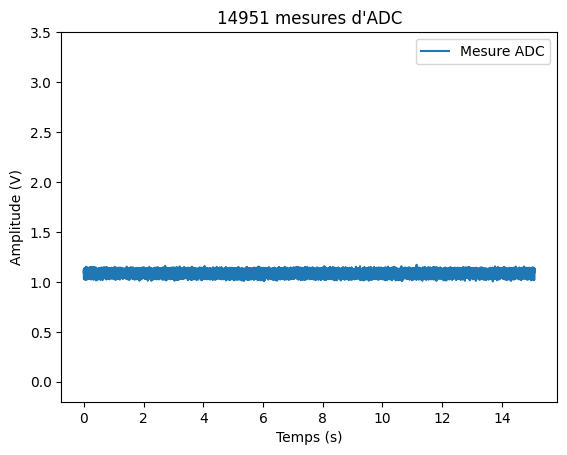

In [101]:
current_measure = measure_release(15000, 1)
plot_adc(current_measure)

In [102]:
import time
import math
import threading

# =================================
# Constantes
# =================================

max_motor_speed = 166.667 #tr/s

# =================================
# Mesure des vibrations en forcée
# =================================

time_table = []
speed_table = []
adc_table = []
accel_table = []
pwm_table = []

def freq2duty(freq):
    duty = int(round(freq/max_motor_speed, 4)*1000)
    # duty is an integer between 0 and 100 (0.x precision when %)
    return duty


def tx_command(length_ms, max_freq, freq_step, min_freq):
    print("Thread %s: starting")
    #nb of points
    max_points = int( (max_freq-min_freq)/freq_step ) + 1 #+1 for step @ 0 Hz
    #initial period of null freq
    uart_send_command(freq2duty(0.0))
    for step in range(0, max_points):
        time.sleep(length_ms/1000)
        freq = max_freq - step*freq_step
        uart_send_command(freq2duty(freq))
        
    #final period of null freq to finish the measure
    uart_send_command(freq2duty(0.0))
    print("Thread %s: finishing")

        
'''
# Parametres

te_ms : Période d'échantillonage
length_ms : Longueur de mesure PAR fréquence
max_freq : frequence stimulée max
freq_step : pas de frequence
min_freq : frequence stimulée min

# Description

La fonction initie une série de mesures bloquantes.
La commande part de la fréquence max vers la fréquence min avec un pas freq_step
Le post-traitement est directement fait par la fonction
'''        

def measure_forced_vibrations(te_ms, length_ms, max_freq, freq_step, min_freq):
    #reboot input buffer
    global time_table, speed_table, adc_table, accel_table, pwm_table
    core_measure = []
    
    measuring_time = (int( (max_freq-min_freq)/freq_step ) + 1)*(length_ms/1000)
    reading_points = int(measuring_time*1000/te_ms)
    
    thread_command = threading.Thread(target=tx_command, 
                                      args=(length_ms, max_freq, freq_step, min_freq), 
                                      daemon = True)
    # =================================
    # Mesures
    # =================================
    print("=== Lancement des mesures ===")
    print("Temps total: "+str(measuring_time)+"s"+" | "+str(measuring_time/60)+ "min")
    print("--> Début de la mesure")
    thread_command.start()
    core_measure = read_data(reading_points)
    
    print("--> Fin de la mesure")
    # =================================
    # Traitements
    # =================================
    print("=== Traitement des mesures ===")
    print("--> Traitement principal")
    computed_data = (compute_data_table(core_measure))
    print("--> Découpage des tables")
    return (all_getTable(computed_data))
    print("--> Retour")

In [13]:
current_measure = measure_forced_vibrations(te_ms=1, length_ms=30000, max_freq=10, freq_step=0.5, min_freq=0)

=== Lancement des mesures ===
Temps total: 630.0s | 10.5min
--> Début de la mesure
Thread %s: starting


Exception in thread Thread-10 (tx_command):
Traceback (most recent call last):
  File "/usr/lib/python3.10/threading.py", line 1016, in _bootstrap_inner
    self.run()
  File "/usr/lib/python3.10/threading.py", line 953, in run
    self._target(*self._args, **self._kwargs)
  File "/tmp/ipykernel_55383/3969310603.py", line 32, in tx_command


NameError: name 'read_data' is not defined

  File "/tmp/ipykernel_55383/4151029496.py", line 72, in uart_send_command
NameError: name 'data_serial' is not defined


In [103]:
print(time_table)
#print(adc_table)

[]


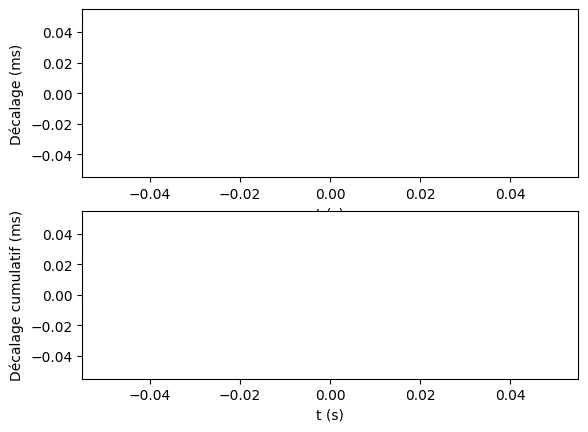

In [104]:
def compute_error_time(time_table, period):
    time_error_table =[0]*len(time_table)
    cumulative_error =[0]*len(time_table)
    for i in range(1, len(time_table)):
        if (i == 1):
            time_error_table[i] = round(time_table[i] - period, 3)
            cumulative_error[i] = round(time_table[i] - period, 3)
        elif (i != 1):
            time_error_table[i] = round(time_table[i] - time_table[i-1] - period, 3)
            if (round(time_table[i] - time_table[i-1] - period, 3) < period):
                cumulative_error[i] = cumulative_error[i-1] + round(time_table[i] - time_table[i-1] - period, 3)
            else:
                cumulative_error[i] = cumulative_error[i-1]
            
            
    plt.subplot(2,1,1)
    plt.step(time_table[10:len(time_table)],time_error_table[10:len(time_table)])
    plt.xlabel("t (s)")
    plt.ylabel("Décalage (ms)")
    
    plt.subplot(2,1,2)
    plt.step(time_table,cumulative_error)
    plt.xlabel("t (s)")
    plt.ylabel("Décalage cumulatif (ms)")

compute_error_time(time_table, 0.1)

In [105]:
print(len(current_measure))

14951


In [16]:
#current_table = measure_release(15000, 1)

# ==========================
# Plot data
# ==========================

def extract_table(dt, index):
    ndt = [0]*len(dt)
    for i in range(len(dt)):
        ndt[i] = dt[i][index]
    return ndt

def plot_speed(dt):
    time_table = extract_table(dt, 0)
    pwm_table = extract_table(dt, 3)
    speed_table = extract_table(dt, 4)
    max_len = min(len(time_table), min(len(pwm_table),len(speed_table)))
    plt.plot(time_table[0:max_len],pwm_table[0:max_len], label = "Commande")
    plt.plot(time_table[0:max_len], speed_table[0:max_len], label = "Vitesse")
    plt.xlabel("Temps (s)")
    plt.ylim([-100, 500])
    plt.ylabel("Vitesse (rpm)")
    plt.title(str(len(time_table))+" mesures d'ADC en série")
    plt.legend()
    
def plot_adc(dt):
    time_table = extract_table(dt, 0)
    print(len(time_table))
    accel_table = extract_table(dt, 1)
    print(len(accel_table))
    max_len = min(len(time_table), len(accel_table))
    plt.step(time_table[0:max_len],accel_table[0:max_len], label = "Mesure ADC")
    plt.xlabel("Temps (s)")
    plt.ylim([-0.2, 3.5])
    plt.ylabel("Amplitude (V)")
    plt.title(str(len(time_table))+" mesures d'ADC")
    plt.legend()
    
def plot_accel(dt):
    time_table = extract_table(dt, 0)
    print(len(time_table))
    accel_table = extract_table(dt, 2)
    print(len(accel_table))
    max_len = min(len(time_table), len(accel_table))
    plt.step(time_table[0:max_len],accel_table[0:max_len], label = "Mesure d'accelero")
    plt.xlabel("Temps (s)")
    plt.ylim([-3.2, 3.2])
    plt.ylabel("Amplitude (G)")
    plt.title(str(len(time_table))+" mesures d'accelero")
    plt.legend()

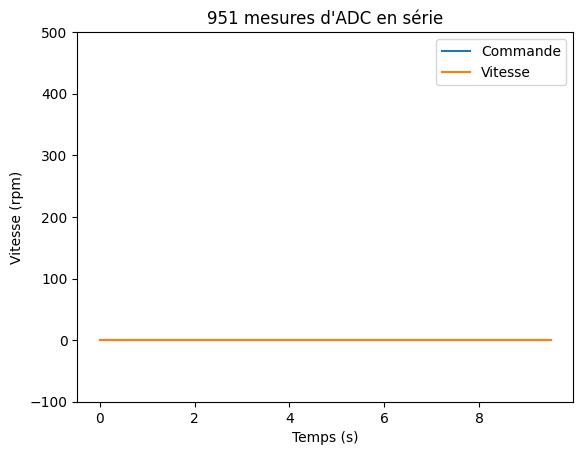

In [24]:
plot_speed(current_measure)

951
951


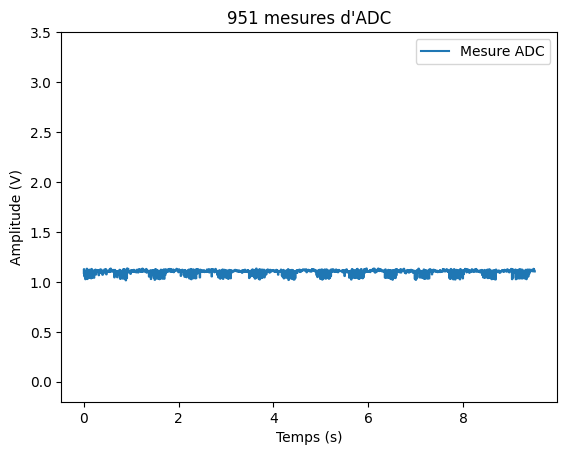

In [25]:
plot_adc(current_measure)

## Post-traitement des données

### Constantes

In [128]:
# =======================================
#   Calcul moment d'inertie du volant
# =======================================


def Iv(R, r, m):
    result = 0.5*m*(r+R)**2
    return result

def IvAtMotor(R,r, m, reduction):
    result = (1/reduction**2)*Iv(R,r,m)
    return result

r_volant = 23e-3 #m
R_volant = 148e-3 #m
m = 2.3 #kg
reduction = 15.88 #tr_e / tr_s


Ivolant = round(IvAtMotor(R_volant, r_volant, m, reduction), 6)
print(Ivolant)

Imoteur = 2.5e-5 #Kg/m2

Vmax = 24 #V
Imax = 3.3 #A

0.000133


### Fonctions

In [160]:
import math
import numpy as np

def Kj_moteur(speed, unit="rad.s"): #les deux variables doivent être des numpy array
    #defines the space
    result = None
    if (unit == "rad.s"):
        result = 0.5*(Imoteur + Ivolant)*(speed)**2
    elif (unit == "rpm"):
        rad_speed = speed * 2 * (np.pi/60)
        result = 0.5*(Imoteur + Ivolant)*(rad_speed)**2
    
    #to avoid spreading calculations errors
    result = np.round(result, 3)
    return result

def Kj_volant(speed, unit="rad.s"): #les deux variables doivent être des numpy array
    #defines the space
    result = None
    if (unit == "rad.s"):
        result = 0.5*(Ivolant)*(speed)**2
    elif (unit == "rpm"):
        rad_speed = speed * 2 * (np.pi/60)
        result = 0.5*(Ivolant)*(rad_speed)**2
    
    #to avoid spreading calculations errors
    result = np.round(result, 3)
    return result

def Kj_elec_moteur(current, pwm, te):
    result = [0]*len(current)
    percentage = pwm/1000
    for i in range(len(current)):
        result[i] = current[i]*24*percentage[i]*round(te/1000, 4)
    
    result = np.array(result)
    result = np.round(result, 3)
    return result

def n_rendement(out_array, in_array):
    min_len_array = min(len(out_array),len(in_array))
    result = np.array([0]*min_len_array)
    
    for i in range(min_len_array):
        result[i] = out_array[i]/in_array[i]
                        
    result = np.round(result, 3)
    return result
                        
def global_rendement(speed, unit, current, pwm, te):
    Kj_moteur = Kj_moteur(speed, unit)
    Kj_volant = Kj_volant(speed, unit)
    Kj_elec_moteur = Kj_elec_moteur(current, pwm, te)
                        
    result = n_rendement(Kj_volant, Kj_moteur)
    result = n_rendement(result, Kj_elec_moteur)
    result = np.round(result, 3)
                        
    return result

def position(p0, speed, te):
    result = np.array([0]*len(speed))
    ## Initial position
    result[0] = 0.5*speed[0]*te +p0
    for i in range(1,len(result)):
        result[i] = 0.5*speed[i]*te + speed[i-1]*te + result[0]
        
    result = np.round(result, 3)
    return result

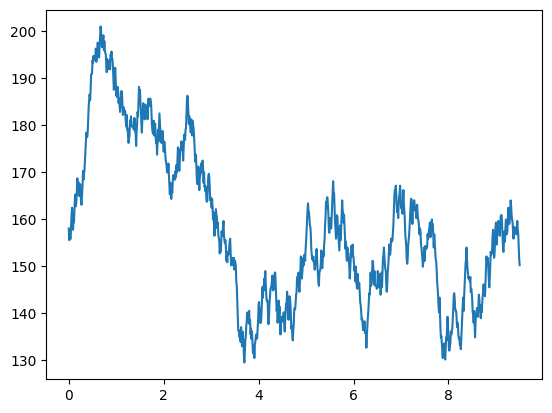

In [161]:
import random

current = np.array(extract_table(current_measure, 1))
pwm = [0]*len(current)
speed = [0]*len(current)
pwm_base = 500
for i in range(len(current)):
    pwm_base = pwm_base + random.randint(-10, 10)
    if (pwm_base > 1000):
        pwm_base = 1000
    elif (pwm_base < 0):
        pwm_base = 0
    pwm[i] = pwm_base
    
    speed[i] = round(2*(np.pi/60)*3000*(pwm[i]/1000), 3)
pwm = np.array(pwm)
speed = np.array(speed)

tm = [0]*len(current)
for i in range(0,len(tm)):
    tm[i] = i*0.01
    
plt.plot(tm, speed)

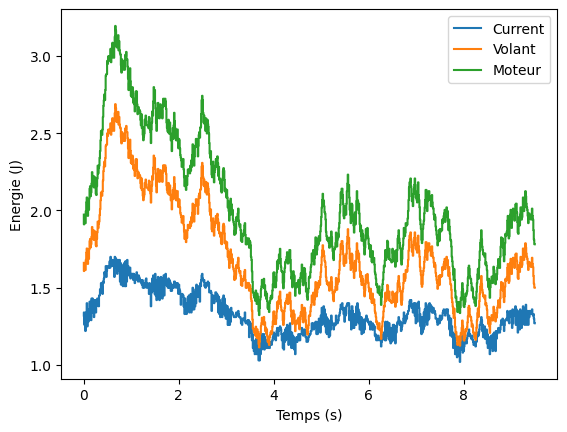

In [162]:
result_current = Kj_elec_moteur(current, pwm, 10)
result_volant = Kj_volant(speed)
result_moteur = Kj_moteur(speed)


plt.step(tm, result_current*10, label = "Current")
plt.step(tm, result_volant, label = "Volant")
plt.step(tm, result_moteur, label = "Moteur")
plt.ylabel("Energie (J)")
plt.xlabel("Temps (s)")
plt.legend()